# Linear regression from scratch: predicting credit card balance

Linear regression implemented with NumPy only (no ML library for the model), applied to the
*Credit* dataset (400 card holders, 11 features). The notebook goes from a single-predictor
model to a multivariate model with one-hot encoded categoricals, handles collinearity with
variance inflation factors, and checks every result against scikit-learn.

## Problem

Given a card holder's income, credit limit, credit rating, number of cards, age, education and
four categorical attributes (gender, student status, marital status, ethnicity), predict the
**balance** on the card. Two questions:

1. How much of the balance can a single predictor (the credit rating) explain?
2. How much better does a multivariate model do, and what has to be done about near-duplicate
   features such as `Limit` and `Rating`?

Dataset: the *Credit* data from *An Introduction to Statistical Learning* (James, Witten,
Hastie, Tibshirani), https://www.statlearning.com/.

## Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Palette (categorical slots 1-3 + neutral ink/grid)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b8b7b2", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2,
    "font.size": 10,
})
np.set_printoptions(precision=4, suppress=True)

df = pd.read_excel("data/credit_card.xlsx").drop(columns="ID")
print(df.shape)
df.head()

(400, 11)


,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
0,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
1,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
2,104.593,7075,514,4,71,11,Male,No,No,Asian,580
3,148.924,9504,681,3,36,11,Female,No,No,Asian,964
4,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


In [2]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Income,400.0,45.22,35.24,10.35,21.01,33.12,57.47,186.63
Limit,400.0,4735.60,2308.20,855.00,3088.00,4622.50,5872.75,13913.00
Rating,400.0,354.94,154.72,93.00,247.25,344.00,437.25,982.00
Cards,400.0,2.96,1.37,1.00,2.00,3.00,4.00,9.00
Age,400.0,55.67,17.25,23.00,41.75,56.00,70.00,98.00
Education,400.0,13.45,3.13,5.00,11.00,14.00,16.00,20.00
Balance,400.0,520.02,459.76,0.00,68.75,459.50,863.00,1999.00


In [3]:
for col in ["Gender", "Student", "Married", "Ethnicity"]:
    print(col, {k: int(v) for k, v in df[col].value_counts().items()})
print("Missing values:", int(df.isna().sum().sum()))

Gender {'Female': 207, 'Male': 193}
Student {'No': 360, 'Yes': 40}
Married {'Yes': 245, 'No': 155}
Ethnicity {'Caucasian': 199, 'Asian': 102, 'African American': 99}
Missing values: 0


### Distributions of the response and the main predictor

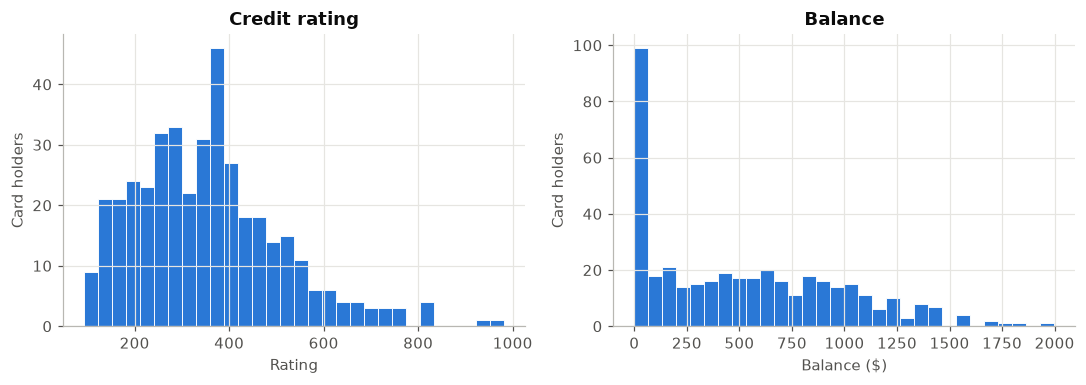

Card holders with zero balance: 90 of 400


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(df["Rating"], bins=30, color=C1, edgecolor="white", linewidth=0.6)
axes[0].set(title="Credit rating", xlabel="Rating", ylabel="Card holders")
axes[1].hist(df["Balance"], bins=30, color=C1, edgecolor="white", linewidth=0.6)
axes[1].set(title="Balance", xlabel="Balance ($)", ylabel="Card holders")
plt.tight_layout()
plt.show()
print(f"Card holders with zero balance: {(df['Balance'] == 0).sum()} of {len(df)}")

Balance has a spike at zero (90 holders carry no balance) and a long right tail. That matters
later: a linear model cannot predict exactly zero for a whole group, which shows up in the
residual plot.

### Rating vs Balance and the correlation structure

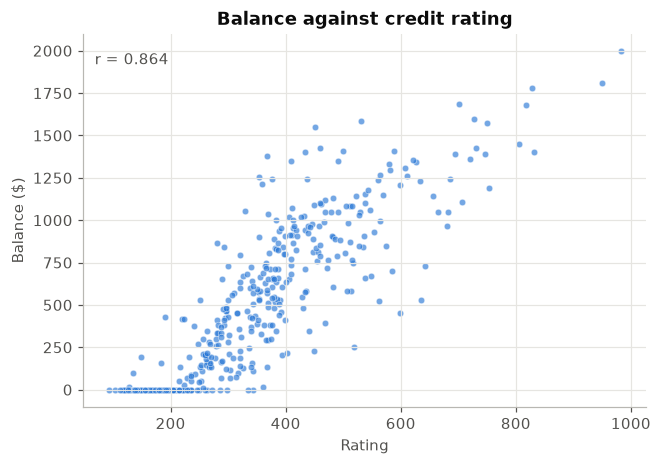

In [5]:
numeric = df.select_dtypes("number")
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.scatter(df["Rating"], df["Balance"], s=18, color=C1, alpha=0.65, edgecolor="white", linewidth=0.4)
ax.set(title="Balance against credit rating", xlabel="Rating", ylabel="Balance ($)")
ax.text(0.02, 0.95, f"r = {corr.loc['Rating', 'Balance']:.3f}", transform=ax.transAxes, color=INK2, va="top")
plt.show()

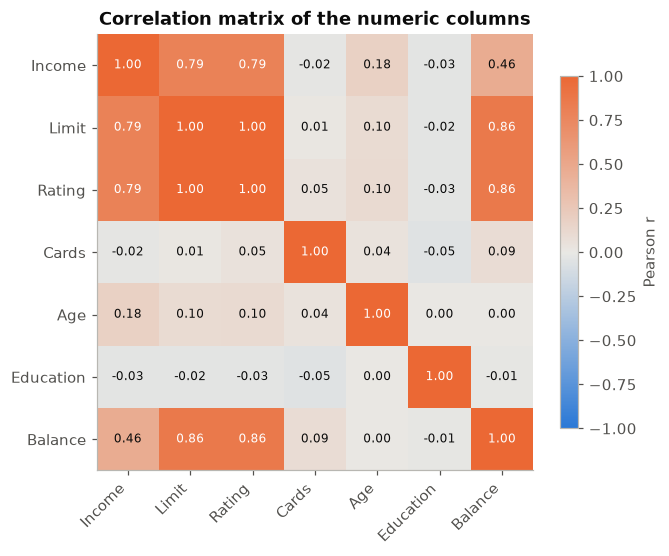

corr(Rating, Balance) = 0.8636
corr(Income, Balance) = 0.4637
corr(Limit, Balance)  = 0.8617
corr(Limit, Rating)   = 0.9969


In [6]:
div = LinearSegmentedColormap.from_list("div", [C1, "#e9e8e4", C2])
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix of the numeric columns")
plt.savefig("images/correlation_heatmap.png")
plt.show()

print(f"corr(Rating, Balance) = {corr.loc['Rating', 'Balance']:.4f}")
print(f"corr(Income, Balance) = {corr.loc['Income', 'Balance']:.4f}")
print(f"corr(Limit, Balance)  = {corr.loc['Limit', 'Balance']:.4f}")
print(f"corr(Limit, Rating)   = {corr.loc['Limit', 'Rating']:.4f}")

Three things to take from the heatmap:

- `Rating` and `Limit` are the strongest single predictors of `Balance` (r ≈ 0.86 each).
- `Rating` and `Limit` are almost the same variable (r ≈ 0.997). Putting both in a model is a
  collinearity problem, handled in the multivariate section.
- `Age`, `Education` and `Cards` are essentially uncorrelated with `Balance`.

## Method

Everything below is NumPy. For a design matrix $X$ (with a leading column of ones) and
response $y$, the ordinary least squares coefficients are the solution of the normal equation

$$\hat\beta = (X^\top X)^{-1} X^\top y .$$

`np.linalg.solve` is used instead of forming the inverse, which is the numerically sane way to
solve the same system. Metrics:

$$\mathrm{RMSE} = \sqrt{\tfrac{1}{n}\sum (y_i-\hat y_i)^2}, \qquad
\mathrm{MAE} = \tfrac{1}{n}\sum |y_i-\hat y_i|, \qquad
R^2 = 1 - \frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}.$$

The variance inflation factor of feature $j$ is $\mathrm{VIF}_j = 1/(1-R_j^2)$ where $R_j^2$
is the $R^2$ of regressing feature $j$ on all the other features, using the same solver.

In [7]:
def train_test_split_np(X, y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    n_test = int(len(y) * test_size)
    test, train = idx[:n_test], idx[n_test:]
    return X[train], X[test], y[train], y[test]

def add_intercept(X):
    return np.column_stack([np.ones(len(X)), X])

def fit_ols(X, y):
    # Solve (X'X) beta = X'y
    Xb = add_intercept(X)
    return np.linalg.solve(Xb.T @ Xb, Xb.T @ y)

def predict(X, beta):
    return add_intercept(X) @ beta

def rmse(y, yhat):
    return float(np.sqrt(np.mean((y - yhat) ** 2)))

def mae(y, yhat):
    return float(np.mean(np.abs(y - yhat)))

def r2(y, yhat):
    ss_res = np.sum((y - yhat) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return float(1 - ss_res / ss_tot)

def evaluate(X_tr, X_te, y_tr, y_te):
    beta = fit_ols(X_tr, y_tr)
    tr, te = predict(X_tr, beta), predict(X_te, beta)
    return beta, {
        "train_R2": r2(y_tr, tr), "train_RMSE": rmse(y_tr, tr),
        "test_R2": r2(y_te, te), "test_RMSE": rmse(y_te, te), "test_MAE": mae(y_te, te),
    }

def vif(X, names):
    out = {}
    for j in range(X.shape[1]):
        others = np.delete(X, j, axis=1)
        beta = fit_ols(others, X[:, j])
        out[names[j]] = 1 / (1 - r2(X[:, j], predict(others, beta)))
    return pd.Series(out, name="VIF")

## Results

### Single predictor: Balance ~ Rating

In [8]:
y = df["Balance"].to_numpy(dtype=float)
X1 = df[["Rating"]].to_numpy(dtype=float)
X1_tr, X1_te, y_tr, y_te = train_test_split_np(X1, y)
print(f"train size {len(y_tr)}, test size {len(y_te)}")

beta1, m1 = evaluate(X1_tr, X1_te, y_tr, y_te)
print(f"Balance = {beta1[0]:.2f} + {beta1[1]:.4f} * Rating")
pd.Series(m1).round(4)

train size 320, test size 80
Balance = -389.12 + 2.5360 * Rating


train_R2        0.7501
train_RMSE    231.9776
test_R2         0.7228
test_RMSE     230.6465
test_MAE      168.8260
dtype: float64

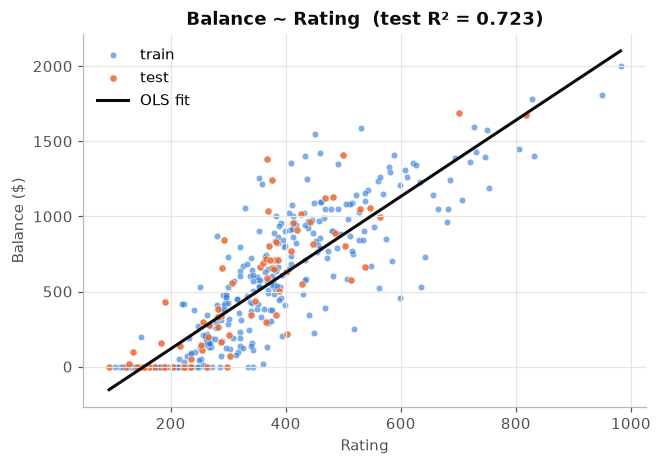

In [9]:
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.scatter(X1_tr[:, 0], y_tr, s=18, color=C1, alpha=0.6, edgecolor="white", linewidth=0.4, label="train")
ax.scatter(X1_te[:, 0], y_te, s=22, color=C2, alpha=0.85, edgecolor="white", linewidth=0.4, label="test")
xs = np.linspace(X1.min(), X1.max(), 50).reshape(-1, 1)
ax.plot(xs, predict(xs, beta1), color=INK, linewidth=2, label="OLS fit")
ax.set(title=f"Balance ~ Rating  (test R² = {m1['test_R2']:.3f})", xlabel="Rating", ylabel="Balance ($)")
ax.legend(frameon=False)
plt.savefig("images/fit_rating_balance.png")
plt.show()

#### Does the relationship differ for students?

Fitting the same one-feature model separately to students and non-students.

In [10]:
rows = []
for group in ["Yes", "No"]:
    sub = df[df["Student"] == group]
    Xg = sub[["Rating"]].to_numpy(dtype=float)
    yg = sub["Balance"].to_numpy(dtype=float)
    Xg_tr, Xg_te, yg_tr, yg_te = train_test_split_np(Xg, yg)
    b, m = evaluate(Xg_tr, Xg_te, yg_tr, yg_te)
    rows.append({"group": f"Student = {group}", "n": len(sub), "intercept": b[0], "slope": b[1], **m})
rows.append({"group": "All", "n": len(df), "intercept": beta1[0], "slope": beta1[1], **m1})
student_tbl = pd.DataFrame(rows).set_index("group").round(4)
student_tbl

,n,intercept,slope,train_R2,train_RMSE,test_R2,test_RMSE,test_MAE
group,,,,,,,,
Student = Yes,40,-134.9843,2.7767,0.7376,263.3805,-0.3342,225.7880,195.2617
Student = No,360,-421.1324,2.5137,0.8014,195.8453,0.8493,168.7205,133.4369
All,400,-389.1239,2.5360,0.7501,231.9776,0.7228,230.6465,168.8260


The slope is similar in both groups, but the intercept differs by almost 300 dollars: at the
same rating, students carry a markedly higher balance. A single line through all 400 holders
cannot express that, which is one argument for adding `Student` as a feature.

A caveat on the student row: only 40 holders are students, so its test set has 8 points and the
test metrics (including the negative test R²) are too noisy to read much into. The training fit
is the reliable part of that row.

### Multivariate model: all features, one-hot encoded

The four categorical columns are one-hot encoded with the first level dropped. Keeping all
levels plus an intercept would make $X^\top X$ singular (the "dummy variable trap"), because
the dummies of one variable sum to the intercept column.

In [11]:
cat_cols = ["Gender", "Student", "Married", "Ethnicity"]
encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=float)
feature_names_all = [c for c in encoded.columns if c != "Balance"]
X_all = encoded[feature_names_all].to_numpy(dtype=float)
print(feature_names_all)

['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education', 'Gender_Male', 'Student_Yes', 'Married_Yes', 'Ethnicity_Asian', 'Ethnicity_Caucasian']


#### Collinearity check

Before fitting: how well can each feature be predicted from the others? A VIF above 10 is the
usual alarm threshold. The condition number of $X^\top X$ tells the same story globally.

In [12]:
vif_before = vif(X_all, feature_names_all)
cond_before = np.linalg.cond(add_intercept(X_all).T @ add_intercept(X_all))
print(f"corr(Limit, Rating) = {corr.loc['Limit', 'Rating']:.4f}")
print(f"condition number of X'X (all features): {cond_before:.3e}")
vif_before.round(2).to_frame()

corr(Limit, Rating) = 0.9969
condition number of X'X (all features): 1.501e+09


,VIF
Income,2.79
Limit,234.03
Rating,235.85
Cards,1.45
Age,1.05
Education,1.02
Gender_Male,1.01
Student_Yes,1.03
Married_Yes,1.04
Ethnicity_Asian,1.55


`Limit` and `Rating` inflate each other's variance by a factor well above 100: the model
cannot tell their individual effects apart, and their coefficients would be unstable
(small changes in the training sample would swing them wildly, possibly with opposite signs).

**Handling it:** drop `Limit`. It is the near-duplicate of `Rating` (r = 0.997), and
`Rating` is the slightly stronger single predictor of `Balance`. After dropping it every VIF
falls back to the normal range.

In [13]:
feature_names = [f for f in feature_names_all if f != "Limit"]
X_mv = encoded[feature_names].to_numpy(dtype=float)
vif_after = vif(X_mv, feature_names)
cond_after = np.linalg.cond(add_intercept(X_mv).T @ add_intercept(X_mv))
print(f"condition number of X'X (without Limit): {cond_after:.3e}")
pd.DataFrame({"VIF with Limit": vif_before, "VIF without Limit": vif_after}).reindex(feature_names_all).round(2)

condition number of X'X (without Limit): 7.469e+06


,VIF with Limit,VIF without Limit
Income,2.79,2.78
Limit,234.03,NaN
Rating,235.85,2.73
Cards,1.45,1.02
Age,1.05,1.05
Education,1.02,1.01
Gender_Male,1.01,1.01
Student_Yes,1.03,1.02
Married_Yes,1.04,1.03
Ethnicity_Asian,1.55,1.55


#### Fit and evaluate on the held-out test set

In [14]:
X_tr, X_te, y_tr, y_te = train_test_split_np(X_mv, y)
beta_mv, m_mv = evaluate(X_tr, X_te, y_tr, y_te)

coef_tbl = pd.DataFrame({"coefficient": beta_mv}, index=["intercept"] + feature_names).round(4)
coef_tbl

,coefficient
intercept,-565.2189
Income,-7.8363
Rating,3.9904
Cards,4.6937
Age,-0.6644
Education,-0.1491
Gender_Male,8.6803
Student_Yes,420.1647
Married_Yes,-14.3951
Ethnicity_Asian,25.1654


In [15]:
comparison = pd.DataFrame({"Balance ~ Rating": m1, "Multivariate (no Limit)": m_mv}).T
comparison.round(4)

,train_R2,train_RMSE,test_R2,test_RMSE,test_MAE
Balance ~ Rating,0.7501,231.9776,0.7228,230.6465,168.8260
Multivariate (no Limit),0.9522,101.4598,0.9461,101.7201,81.9749


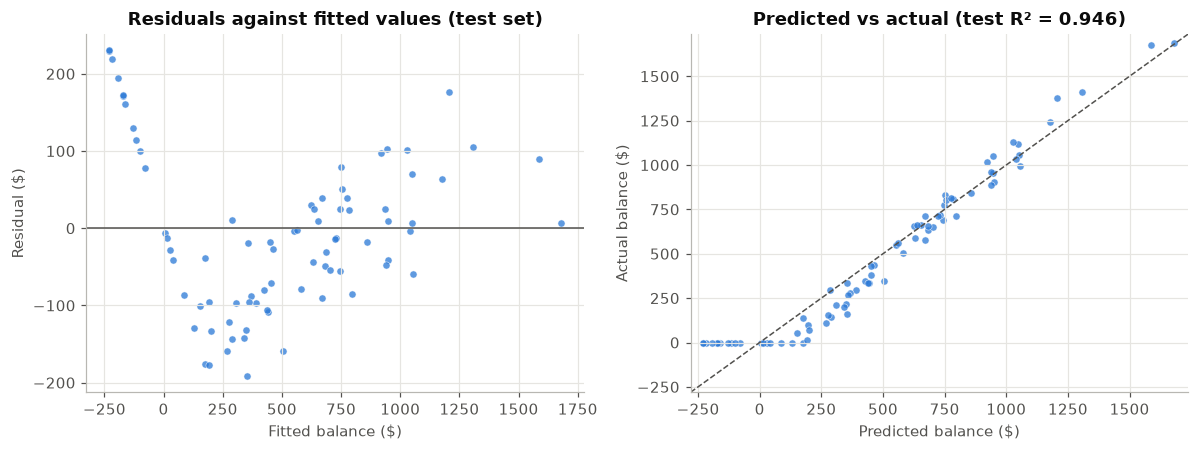

In [16]:
y_hat_te = predict(X_te, beta_mv)
resid = y_te - y_hat_te

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].axhline(0, color=INK2, linewidth=1)
axes[0].scatter(y_hat_te, resid, s=22, color=C1, alpha=0.75, edgecolor="white", linewidth=0.4)
axes[0].set(title="Residuals against fitted values (test set)", xlabel="Fitted balance ($)", ylabel="Residual ($)")

lim = [min(y_te.min(), y_hat_te.min()) - 50, max(y_te.max(), y_hat_te.max()) + 50]
axes[1].plot(lim, lim, color=INK2, linewidth=1, linestyle="--")
axes[1].scatter(y_hat_te, y_te, s=22, color=C1, alpha=0.75, edgecolor="white", linewidth=0.4)
axes[1].set(title=f"Predicted vs actual (test R² = {m_mv['test_R2']:.3f})", xlabel="Predicted balance ($)", ylabel="Actual balance ($)")
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
plt.tight_layout()
plt.savefig("images/residuals.png")
plt.show()

The residual plot has a clear structure: a diagonal streak of points running from the
bottom-left upwards. Those are the zero-balance holders. The model predicts a negative or
small positive balance for them, and because the true value is pinned at exactly 0 the residual
equals minus the prediction. A linear model cannot represent "no balance at all", so the
remaining error is mostly that group, not noise around the line.

### Check against scikit-learn

Same splits, same features. scikit-learn's `LinearRegression` solves the same least squares
problem (via an SVD-based least squares routine rather than the normal equation), so the
coefficients should agree to floating-point precision.

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def sklearn_fit(X_tr, X_te, y_tr, y_te):
    lr = LinearRegression().fit(X_tr, y_tr)
    pred = lr.predict(X_te)
    coefs = np.concatenate([[lr.intercept_], lr.coef_])
    return coefs, {
        "test_R2": r2_score(y_te, pred),
        "test_RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
        "test_MAE": mean_absolute_error(y_te, pred),
    }

sk1, skm1 = sklearn_fit(X1_tr, X1_te, y_tr, y_te)
skmv, skm_mv = sklearn_fit(X_tr, X_te, y_tr, y_te)

coef_compare = pd.DataFrame({
    "from scratch": beta_mv, "scikit-learn": skmv, "abs diff": np.abs(beta_mv - skmv)
}, index=["intercept"] + feature_names)
print(f"Balance ~ Rating: from scratch {beta1}, sklearn {sk1}, max |diff| = {np.abs(beta1 - sk1).max():.2e}")
print(f"Multivariate: max |coefficient diff| = {coef_compare['abs diff'].max():.2e}")
coef_compare.round(6)

Balance ~ Rating: from scratch [-389.1239    2.536 ], sklearn [-389.1239    2.536 ], max |diff| = 1.71e-13
Multivariate: max |coefficient diff| = 1.65e-11


,from scratch,scikit-learn,abs diff
intercept,-565.218890,-565.218890,0.0
Income,-7.836269,-7.836269,0.0
Rating,3.990386,3.990386,0.0
Cards,4.693684,4.693684,0.0
Age,-0.664415,-0.664415,0.0
Education,-0.149095,-0.149095,0.0
Gender_Male,8.680325,8.680325,0.0
Student_Yes,420.164691,420.164691,0.0
Married_Yes,-14.395062,-14.395062,0.0
Ethnicity_Asian,25.165377,25.165377,0.0


In [18]:
metric_compare = pd.DataFrame({
    "Rating only (scratch)": {k: m1[k] for k in ["test_R2", "test_RMSE", "test_MAE"]},
    "Rating only (sklearn)": skm1,
    "Multivariate (scratch)": {k: m_mv[k] for k in ["test_R2", "test_RMSE", "test_MAE"]},
    "Multivariate (sklearn)": skm_mv,
}).T
metric_compare.round(6)

,test_R2,test_RMSE,test_MAE
Rating only (scratch),0.722849,230.646503,168.826008
Rating only (sklearn),0.722849,230.646503,168.826008
Multivariate (scratch),0.946094,101.720064,81.974910
Multivariate (sklearn),0.946094,101.720064,81.974910


## Conclusion

- A single predictor, the credit rating, explains most of the variance in balance, but the
  one-line model misses a large group effect: at equal rating, students hold a much higher
  balance.
- The multivariate model with one-hot encoded categoricals and `Limit` removed improves the
  test metrics substantially (see the comparison table above). The biggest coefficients are
  `Student_Yes` and a negative `Income` effect once rating is held fixed: higher income at the
  same credit rating means a lower balance.
- `Limit` and `Rating` are near-duplicates (r = 0.997, VIF far above 10). Dropping one of them
  removes the collinearity without losing information; the condition number of $X^\top X$ drops
  by orders of magnitude.
- The from-scratch solver reproduces scikit-learn's coefficients and test metrics to
  floating-point precision, which confirms that the implementation (normal equation, split,
  metrics) is correct.
- The remaining error is structural: 90 holders carry a zero balance, and a linear model
  cannot produce a hard zero. A two-part model (classify zero vs non-zero, then regress) would
  be the natural next step.